# EDA: what "deformed" means, and what it implies for modelling

**Question.** About 90% of the training samples are flagged `is_deformed = 1`. What does that flag mean,
and should we treat it as an imbalance to correct?

**Short answer** (details in each section):
- The features look like embeddings from a frozen pretrained encoder. A deformed sample is most likely an input that was corrupted before it was embedded. Deformed vectors are shrunk and shifted toward a common region, and they carry less class information.
- **The test set is also ~90% deformed.** The 90% is the real data distribution, so we should **not** rebalance clean vs deformed.
- Deformation is probably not one single process. A separate group of deformed rows (about 11% of test) is clearly the hardest to classify.
- The supplementary features are much more informative and less affected by deformation, but they exist only for training rows. That makes them a natural teacher signal.
- For the weighted metric, the label imbalance (class 0 is 35% of labelled rows) matters more than the deformed ratio.

**How to run.** Put the competition CSVs in `ie-643-2026-programming-challenge/` at the repository root (see `README.md`),
start Jupyter from the repository root, and use the project `.venv` kernel. The whole notebook runs on CPU in under a minute.

> **About the probes used here.** Sections 4 to 9 measure things with *linear probes*: a standardized ridge classifier
> fitted on fixed features. They are **diagnostic tools for data analysis only**. They do not produce competition predictions,
> and nothing from them feeds into the submission pipeline. The submission models are MLPs/CNNs, as the rules require.

**Contents**
1. Load and check the data
2. Who is in the training set
3. What deformation does to a feature vector (3.1: is there more than one kind?)
4. Probe toolkit
5. Can the deformation flag be recovered from the features?
6. Is the test set deformed too?
7. How much class information survives deformation?
8. Do simple fixes for the deformation shift help?
9. The supplementary features
10. Summary and implications for the plan

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 0
DATA_DIR = Path("ie-643-2026-programming-challenge")

# One fixed colour per group, used in every figure
CLEAN, DEFORMED, TEST = "#2a78d6", "#eb6834", "#1baf7a"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Load and check the data

| File | What it holds |
|---|---|
| `Train_Data.csv` | `sample_id`, 768 features `e0..e767`, `is_deformed`, `Class_Label` (`-1` = unlabelled) |
| `Test_Data.csv` | `sample_id`, 768 features `f0..f767`, no flag, no label |
| `Supplementry_Data.csv` | `sample_id`, 384 features `g0..g383` from a "complementary source", **training rows only** |

In [2]:
train = pd.read_csv(DATA_DIR / "Train_Data.csv")
test = pd.read_csv(DATA_DIR / "Test_Data.csv")
supp = pd.read_csv(DATA_DIR / "Supplementry_Data.csv")
print("train", train.shape, "| test", test.shape, "| supplementary", supp.shape)

train (2076, 771) | test (490, 769) | supplementary (2078, 385)


In [3]:
g_cols = [f"g{i}" for i in range(384)]
empty = supp[g_cols].isna().all(axis=1)
print("supplementary rows that are completely empty:", int(empty.sum()))
print("other missing values in supplementary:", int(supp.loc[~empty, g_cols].isna().sum().sum()))

supp = supp[~empty].reset_index(drop=True)
assert (supp["sample_id"].to_numpy() == train["sample_id"].to_numpy()).all()
print("after dropping the empty rows:", supp.shape, "- sample_ids match train row by row")

supplementary rows that are completely empty: 2
other missing values in supplementary: 0
after dropping the empty rows: (2076, 385) - sample_ids match train row by row


In [4]:
E = train[[f"e{i}" for i in range(768)]].to_numpy()   # train features
F = test[[f"f{i}" for i in range(768)]].to_numpy()    # test features
G = supp[g_cols].to_numpy()                           # supplementary features (train only)
y = train["Class_Label"].to_numpy()
deformed = train["is_deformed"].to_numpy() == 1
labelled = y >= 0

print("missing values - train:", np.isnan(E).sum(), "| test:", np.isnan(F).sum(), "| supplementary:", np.isnan(G).sum())
print("train and test sample_ids are 1..n:",(train["sample_id"] == np.arange(1, len(train) + 1)).all(),
      (test["sample_id"] == np.arange(1, len(test) + 1)).all())

missing values - train: 0 | test: 0 | supplementary: 0
train and test sample_ids are 1..n: True True


**What this shows.**
- 2076 training rows, 490 test rows. The supplementary file has 2 trailing empty rows; after dropping them it has 2076 rows that line up with `Train_Data.csv` row by row.
- No other missing values anywhere, and `sample_id` runs 1..n in both train and test.

## 2. Who is in the training set

In [5]:
status = pd.crosstab(np.where(labelled, "labelled", "unlabelled"), np.where(deformed, "deformed", "clean"),
                     margins=True, margins_name="total")
status.index.name = status.columns.name = None
display(status)
print(f"deformed: {deformed.mean():.1%} of all training rows, {deformed[labelled].mean():.1%} of labelled rows")
print(f"unlabelled: {(~labelled).mean():.1%} of training rows")

,clean,deformed,total
labelled,136,1148,1284
unlabelled,72,720,792
total,208,1868,2076


deformed: 90.0% of all training rows, 89.4% of labelled rows
unlabelled: 38.2% of training rows


In [6]:
per_class = pd.crosstab(y[labelled], np.where(deformed[labelled], "deformed", "clean"))
per_class["total"] = per_class.sum(axis=1)
per_class["share of labelled"] = per_class["total"] / per_class["total"].sum()
per_class["deformed share"] = per_class["deformed"] / per_class["total"]
per_class.index.name = "class"
display(per_class.style.format({"share of labelled": "{:.1%}", "deformed share": "{:.1%}"}))

col_0,clean,deformed,total,share of labelled,deformed share
class,,,,,
0,46,404,450,35.0%,89.8%
1,8,38,46,3.6%,82.6%
2,6,42,48,3.7%,87.5%
3,6,85,91,7.1%,93.4%
4,10,64,74,5.8%,86.5%
5,17,98,115,9.0%,85.2%
6,14,127,141,11.0%,90.1%
7,5,92,97,7.6%,94.8%
8,3,47,50,3.9%,94.0%


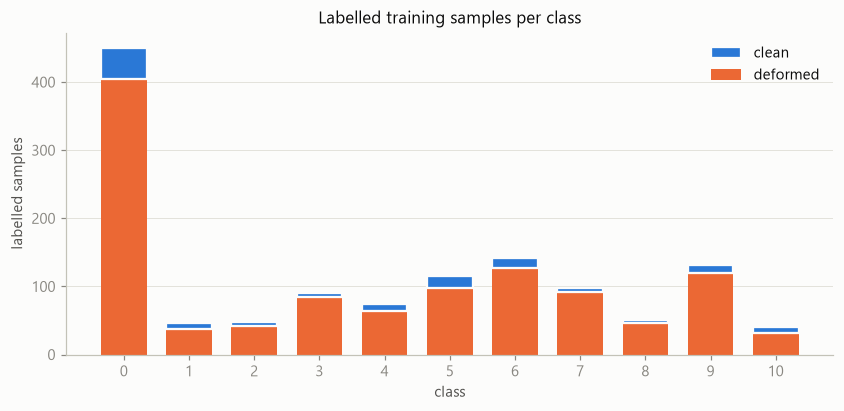

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = per_class.index.to_numpy()
ax.bar(x, per_class["deformed"], width=0.7, color=DEFORMED, label="deformed")
ax.bar(x, per_class["clean"], width=0.7, bottom=per_class["deformed"], color=CLEAN, label="clean",
       edgecolor=SURFACE, linewidth=1.5)
ax.set_xticks(x)
ax.set(xlabel="class", ylabel="labelled samples", title="Labelled training samples per class")
ax.grid(axis="x", visible=False)
handles, names = ax.get_legend_handles_labels()
ax.legend(handles[::-1], names[::-1])          # legend order matches the stack, top first
plt.show()

**What this shows.**
- **90.0%** of training rows are deformed (89.4% of labelled rows). Only **136** labelled rows are clean.
- **38.2%** of training rows (792) are unlabelled, and 720 of those are deformed.
- The deformed share is roughly the same in every class (80–95%), so **deformation is not tied to the class**.
- The labels themselves are imbalanced: **class 0 is 35% of labelled rows** (450). Classes 1, 2, 8 and 10 have only 40–50 each, and clean class 8 has just 3 rows.

## 3. What deformation does to a feature vector

We compare three groups on the 768 main features: clean training rows, deformed training rows, and the test rows.

In [8]:
def row_norms(X):
    return np.linalg.norm(X, axis=1)

def unit(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

def nn_cosine(A, B=None):
    # Cosine similarity of each row of A to its nearest row of B (to its nearest *other* row when B is None)
    S = unit(A) @ unit(A if B is None else B).T
    if B is None:
        np.fill_diagonal(S, -np.inf)
    return S.max(axis=1)

groups = {"train clean": E[~deformed], "train deformed": E[deformed], "test": F}
colors = {"train clean": CLEAN, "train deformed": DEFORMED, "test": TEST}
stats = pd.DataFrame({
    name: {"n": len(X),
           "row norm, mean": row_norms(X).mean(),
           "row norm, std": row_norms(X).std(),
           "per-feature std, mean": X.std(axis=0).mean(),
           "cosine to nearest neighbour in own group": nn_cosine(X).mean()}
    for name, X in groups.items()}).T
stats["n"] = stats["n"].astype(int)
display(stats)

,n,"row norm, mean","row norm, std","per-feature std, mean",cosine to nearest neighbour in own group
train clean,208,13.110,0.583,0.151,0.958
train deformed,1868,12.570,0.387,0.118,0.973
test,490,12.668,0.561,0.128,0.964


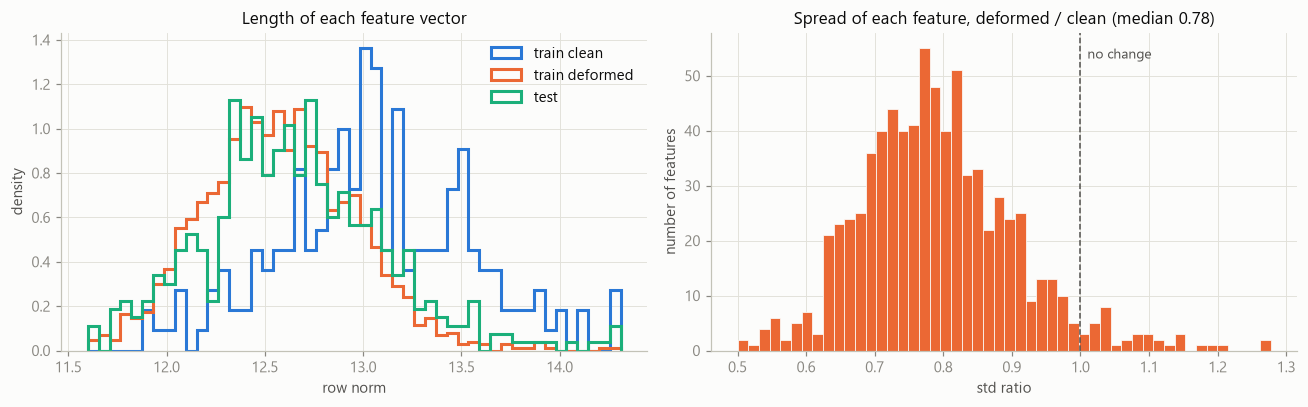

features whose spread shrinks under deformation: 95.4%


In [9]:
std_ratio = E[deformed].std(axis=0) / E[~deformed].std(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
all_norms = np.concatenate([row_norms(X) for X in groups.values()])
bins = np.linspace(*np.percentile(all_norms, [0.5, 99.5]), 50)
for name, X in groups.items():
    ax[0].hist(row_norms(X), bins=bins, density=True, histtype="step", linewidth=2, color=colors[name], label=name)
ax[0].set(title="Length of each feature vector", xlabel="row norm", ylabel="density")
ax[0].legend()

ax[1].hist(std_ratio, bins=50, color=DEFORMED, edgecolor=SURFACE, linewidth=0.5)
ax[1].axvline(1, color=INK2, linestyle="--", linewidth=1)
ax[1].text(1.01, ax[1].get_ylim()[1] * 0.92, "no change", color=INK2, fontsize=9)
ax[1].set(title=f"Spread of each feature, deformed / clean (median {np.median(std_ratio):.2f})",
          xlabel="std ratio", ylabel="number of features")
plt.tight_layout()
plt.show()
print(f"features whose spread shrinks under deformation: {(std_ratio < 1).mean():.1%}")

distance between the clean and deformed mean vectors: 3.11 (a typical row norm is 12.6)
features shifted by more than 1 pooled std: 120 of 768
largest shifts: e625: -1.78, e555: +1.76, e333: +1.74, e173: -1.73, e734: +1.63, e654: -1.59, e381: +1.58, e651: +1.56


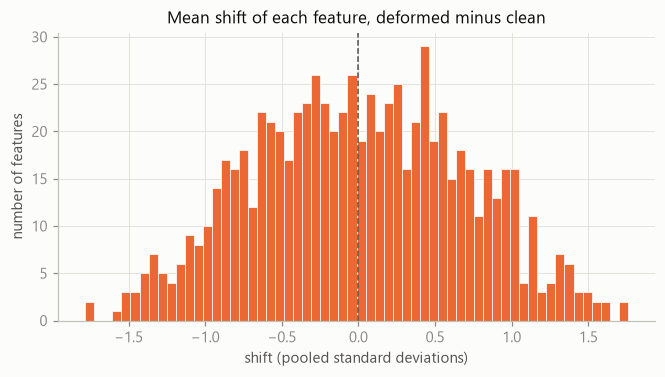

In [10]:
mean_clean, mean_def = E[~deformed].mean(axis=0), E[deformed].mean(axis=0)
shift = (mean_def - mean_clean) / E.std(axis=0)          # shift of each feature, in pooled standard deviations

print(f"distance between the clean and deformed mean vectors: {np.linalg.norm(mean_def - mean_clean):.2f} "
      f"(a typical row norm is {row_norms(E).mean():.1f})")
print(f"features shifted by more than 1 pooled std: {(np.abs(shift) > 1).sum()} of 768")
top = np.argsort(-np.abs(shift))[:8]
print("largest shifts:", ", ".join(f"e{j}: {shift[j]:+.2f}" for j in top))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(shift, bins=60, color=DEFORMED, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(0, color=INK2, linestyle="--", linewidth=1)
ax.set(title="Mean shift of each feature, deformed minus clean", xlabel="shift (pooled standard deviations)",
       ylabel="number of features")
plt.show()

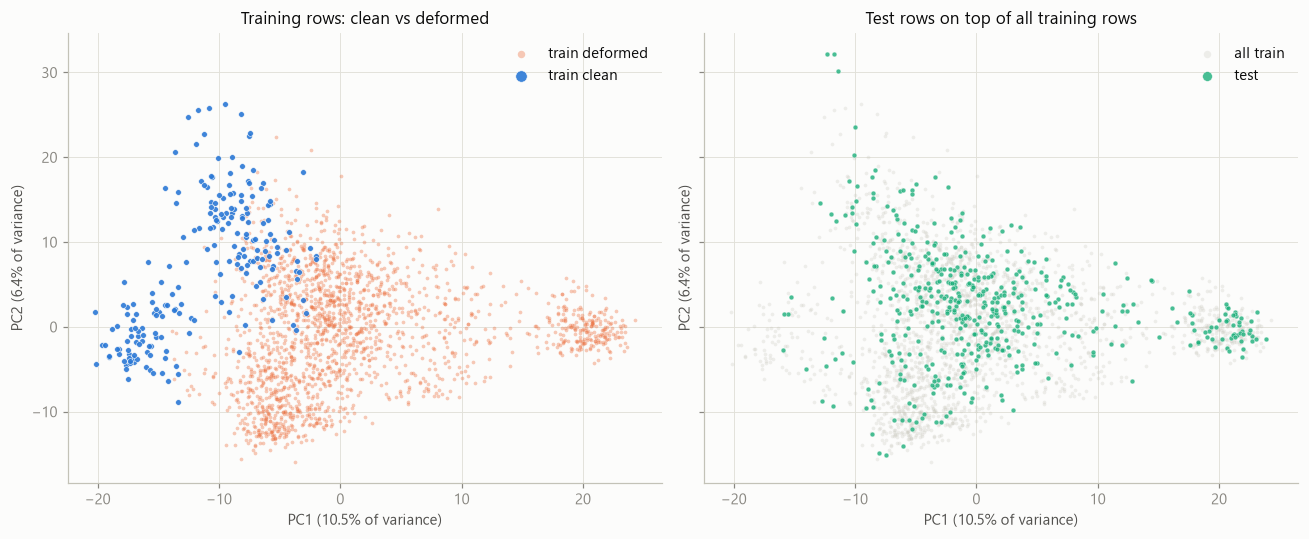

In [11]:
scaler = StandardScaler().fit(E)
pca2 = PCA(n_components=2, random_state=SEED).fit(scaler.transform(E))
P_train, P_test = pca2.transform(scaler.transform(E)), pca2.transform(scaler.transform(F))
ev = pca2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
ax[0].scatter(*P_train[deformed].T, s=6, alpha=0.35, color=DEFORMED, label="train deformed", linewidths=0)
ax[0].scatter(*P_train[~deformed].T, s=14, alpha=0.9, color=CLEAN, label="train clean", edgecolors=SURFACE, linewidths=0.4)
ax[0].set_title("Training rows: clean vs deformed")
ax[1].scatter(*P_train.T, s=6, alpha=0.25, color=AXIS, label="all train", linewidths=0)
ax[1].scatter(*P_test.T, s=10, alpha=0.8, color=TEST, label="test", edgecolors=SURFACE, linewidths=0.3)
ax[1].set_title("Test rows on top of all training rows")
for a in ax:
    a.set(xlabel=f"PC1 ({ev[0]:.1f}% of variance)", ylabel=f"PC2 ({ev[1]:.1f}% of variance)")
    a.legend(markerscale=2, loc="upper right")
plt.tight_layout()
plt.show()

**What this shows.**
- **Shrinkage.** Deformed vectors are shorter (mean row norm 12.57 vs 13.11). Their features vary less: the spread shrinks for 95% of the 768 features, with a median ratio of **0.78**.
- **Shift.** The clean and deformed mean vectors are 3.11 apart, about a quarter of a typical row norm. 120 of the 768 features move by more than one pooled standard deviation, the largest by about ±1.8.
- **Crowding.** Deformed rows sit closer to each other than clean rows do (nearest-neighbour cosine 0.973 vs 0.958).
- **PCA view.** Clean rows sit in their own region at low PC1, and deformed rows spread out to the right. Test rows cover the training cloud, mostly its deformed part. On every statistic in the table, test is much closer to the deformed group.

**What "deformed" most likely means.** The rows look like embeddings from a frozen pretrained encoder (768-d, row norm ≈ 12–13). The pattern above is what corrupting the *input* before encoding usually produces: a less distinctive embedding that shrinks and drifts toward a common "corrupted" region. Section 7 shows that the class signal is still there, only weaker.

*Caveat:* the host defines "deformed" only as "corrupted or deformed". The kind of input (image, text, …) and the corruption are not stated. This reading is inferred from the geometry of the embeddings.

### 3.1 Is there more than one kind of deformation?

The left plot shows a tight group of deformed rows far to the right (large PC1), separated from everything else by a sparse gap.
We look at PC1 on its own, cut at the gap, and check what that group contains.

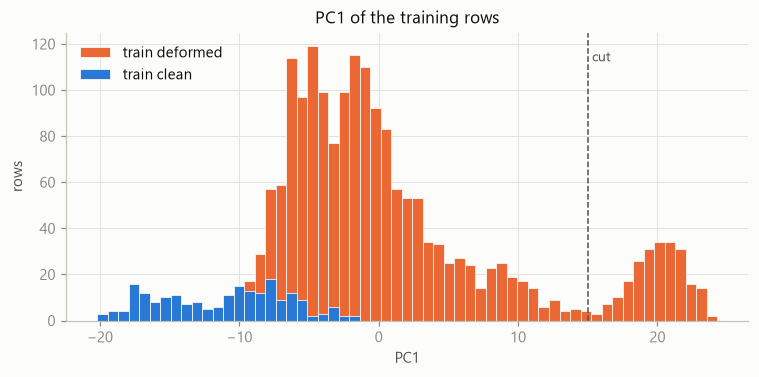

far group: 225 training rows, of which 100% deformed and 0 clean; 55 test rows (11.2% of test)
class mix of the labelled rows in each group:


class,0,1,2,3,4,5,6,7,8,9,10
far group,36%,2%,4%,10%,7%,16%,5%,5%,6%,5%,4%
other deformed,35%,3%,4%,7%,5%,7%,12%,8%,4%,11%,3%


In [12]:
FAR_PC1 = 15          # cut placed in the sparse gap visible in the histogram below
far = P_train[:, 0] > FAR_PC1
far_test = P_test[:, 0] > FAR_PC1

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(P_train[:, 0].min(), P_train[:, 0].max(), 60)
ax.hist(P_train[deformed, 0], bins=bins, color=DEFORMED, label="train deformed", edgecolor=SURFACE, linewidth=0.5)
ax.hist(P_train[~deformed, 0], bins=bins, color=CLEAN, label="train clean", edgecolor=SURFACE, linewidth=0.5)
ax.axvline(FAR_PC1, color=INK2, linestyle="--", linewidth=1)
ax.text(FAR_PC1 + 0.3, ax.get_ylim()[1] * 0.9, "cut", color=INK2, fontsize=9)
ax.set(title="PC1 of the training rows", xlabel="PC1", ylabel="rows")
ax.legend()
plt.show()

print(f"far group: {far.sum()} training rows, of which {deformed[far].mean():.0%} deformed and "
      f"{(far & ~deformed).sum()} clean; {far_test.sum()} test rows ({far_test.mean():.1%} of test)")
mix = pd.DataFrame({
    "far group": pd.Series(y[far & labelled]).value_counts(normalize=True),
    "other deformed": pd.Series(y[~far & deformed & labelled]).value_counts(normalize=True),
}).sort_index().fillna(0)
mix.index.name = "class"
print("class mix of the labelled rows in each group:")
display(mix.T.style.format("{:.0%}"))

**What this shows.**
- The far group has **225 training rows, all deformed, none clean**, and **55 test rows (11.2% of test)**.
- Its class mix matches the other deformed rows (class 0: 36% vs 35%, every class present). So it is **a kind or severity of deformation, not a class**.
- Section 7 shows these are the **hardest rows**: the label probe gets 0.575 out-of-fold accuracy on them, against 0.78 on the other deformed rows and 0.93 on clean rows.

**Implication.** Deformation is probably not one single process. There are at least two regimes: "most deformed rows" and "far group". When we build validation folds, every fold should include far-group rows, and we should track accuracy on them separately. A model that treats the regimes differently (a 3-way detector, or separate heads) is worth trying later.

## 4. Probe toolkit

A **probe** is a deliberately simple classifier fitted on fixed features. Its accuracy shows how much information about a target
is *easy* to read out of those features. It measures the data; it is not a candidate model.

Every probe below is the same pipeline:
- standardize each feature (mean 0, std 1, fitted on the training part of each fold);
- a **ridge classifier** (`alpha = 100`, not tuned): one-vs-rest least squares with an L2 penalty;
- **stratified k-fold cross-validation** (5 folds, 3 for the clean-only subset because clean class 8 has only 3 labelled rows).

We report plain accuracy and **balanced accuracy** (the mean of per-class recalls). Balanced accuracy is our stand-in for the competition's
hidden-weight metric, and for the 90/10 deformation flag it stops "always say deformed" from scoring 90%.

A linear, untuned probe *underestimates* what an MLP can reach, so **only compare the numbers with each other**.

In [13]:
def probe(alpha=100.0):
    # Diagnostic linear probe - not a submission model
    return make_pipeline(StandardScaler(), RidgeClassifier(alpha=alpha))

def folds(n_splits=5):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

def cv_scores(X, t, n_splits=5):
    # Mean cross-validated accuracy and balanced accuracy of the probe
    r = cross_validate(probe(), X, t, cv=folds(n_splits), scoring=["accuracy", "balanced_accuracy"])
    return {"accuracy": r["test_accuracy"].mean(), "balanced accuracy": r["test_balanced_accuracy"].mean()}

def transfer_scores(X_fit, t_fit, X_eval, t_eval):
    # Fit on one set, evaluate on a disjoint set
    p = probe().fit(X_fit, t_fit).predict(X_eval)
    return {"accuracy": accuracy_score(t_eval, p), "balanced accuracy": balanced_accuracy_score(t_eval, p)}

## 5. Can the deformation flag be recovered from the features?

Target: `is_deformed`, using all 2076 training rows (the flag is known for unlabelled rows too). This probe is the **deformation detector**.

In [14]:
detector_cv = cv_scores(E, deformed)
print(f"deformation detector on the 768 main features: accuracy {detector_cv['accuracy']:.3f}, "
      f"balanced accuracy {detector_cv['balanced accuracy']:.3f}")
print(f"(always predicting 'deformed' would give accuracy {deformed.mean():.3f}, balanced accuracy 0.500)")

deformation detector on the 768 main features: accuracy 0.989, balanced accuracy 0.964
(always predicting 'deformed' would give accuracy 0.900, balanced accuracy 0.500)


**What this shows.** A linear probe recovers the flag with **0.964 balanced accuracy** (0.989 plain accuracy, against a 0.900 "always deformed" floor).
Deformation leaves a strong, consistent signature in the features. So when a model needs the flag at test time, where it is not given, we can predict it reliably. In the final pipeline that detector would be a small MLP.

## 6. Is the test set deformed too?

The test file has no flag, but the overview says it contains both kinds of sample. Four independent checks:
1. Fit the detector on all training rows and apply it to the test rows.
2. Is the test mean vector closer to the clean mean or to the deformed mean?
3. For each test row, is its nearest training row clean or deformed?
4. **Adversarial validation**: can a probe tell training rows from test rows at all? (AUC 0.5 means it cannot.)

In [15]:
detector = probe().fit(E, deformed)
test_flag = detector.predict(F)
print(f"1. detector predicts {test_flag.mean():.1%} of test rows as deformed "
      f"(training set: {deformed.mean():.1%})")

mean_test = F.mean(axis=0)
print(f"2. distance of the test mean to the clean mean: {np.linalg.norm(mean_test - mean_clean):.2f}, "
      f"to the deformed mean: {np.linalg.norm(mean_test - mean_def):.2f}")

nn_def = nn_cosine(F, E[deformed]) > nn_cosine(F, E[~deformed])
print(f"3. nearest training row is deformed for {nn_def.mean():.1%} of test rows")

X_adv = np.vstack([E, F])
t_adv = np.r_[np.zeros(len(E), bool), np.ones(len(F), bool)]
adv_score = cross_val_predict(probe(), X_adv, t_adv, cv=folds(), method="decision_function")
print(f"4. train-vs-test adversarial AUC: {roc_auc_score(t_adv, adv_score):.3f}")

1. detector predicts 90.6% of test rows as deformed (training set: 90.0%)
2. distance of the test mean to the clean mean: 2.85, to the deformed mean: 0.64
3. nearest training row is deformed for 93.5% of test rows


4. train-vs-test adversarial AUC: 0.576


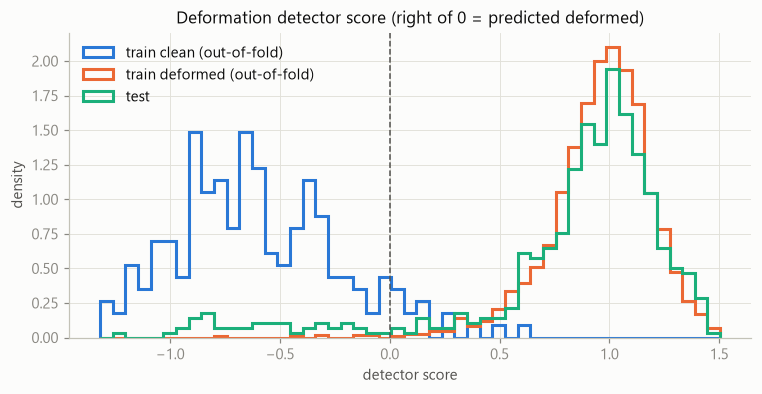

In [16]:
oof_score = cross_val_predict(probe(), E, deformed, cv=folds(), method="decision_function")   # out-of-fold for train
test_score = detector.decision_function(F)

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(*np.percentile(np.r_[oof_score, test_score], [0.5, 99.5]), 50)
ax.hist(oof_score[~deformed], bins=bins, density=True, histtype="step", linewidth=2, color=CLEAN, label="train clean (out-of-fold)")
ax.hist(oof_score[deformed], bins=bins, density=True, histtype="step", linewidth=2, color=DEFORMED, label="train deformed (out-of-fold)")
ax.hist(test_score, bins=bins, density=True, histtype="step", linewidth=2, color=TEST, label="test")
ax.axvline(0, color=INK2, linestyle="--", linewidth=1)
ax.set(title="Deformation detector score (right of 0 = predicted deformed)", xlabel="detector score", ylabel="density")
ax.legend(loc="upper left")
plt.show()

**What this shows.** All four checks agree:
1. The detector calls **90.6%** of test rows deformed (90.0% in train).
2. The test mean lies **0.64** from the deformed mean and 2.85 from the clean mean.
3. The nearest training row is deformed for **93.5%** of test rows. That is close to the 90% base rate, and slightly above it because deformed rows are packed more densely.
4. Train-vs-test adversarial AUC is **0.576**. Train and test are nearly indistinguishable; there is a slight shift, but it is small.

In the histogram, the test scores trace the deformed curve, with a small bump on the clean side (about 9% of test).

**Conclusion: the test set has the same ~90/10 mix as training.** The 90% is the real data distribution, not an imbalance to correct.
Downsampling deformed rows or oversampling clean rows to 50/50 would tune the model for the ~10% of test that is clean.
Deformed rows are the main target. Validation should keep the same mix and report clean and deformed accuracy separately.

## 7. How much class information survives deformation?

Label probes on the labelled rows, first within each group, then **transfer** probes that fit on one group and evaluate on the other.
"Always predict class 0" is shown as a floor for plain accuracy.

In [17]:
subsets = {"clean only": (labelled & ~deformed, 3), "deformed only": (labelled & deformed, 5), "all labelled": (labelled, 5)}
rows = {}
for name, (mask, k) in subsets.items():
    rows[name] = {"n": int(mask.sum()), "folds": k, **cv_scores(E[mask], y[mask], k),
                  "always class 0": (y[mask] == 0).mean()}
label_probe = pd.DataFrame(rows).T.astype({"n": int, "folds": int})
display(label_probe)

,n,folds,accuracy,balanced accuracy,always class 0
clean only,136,3,0.845,0.729,0.338
deformed only,1148,5,0.734,0.556,0.352
all labelled,1284,5,0.774,0.635,0.350


In [18]:
# Where does the all-labelled probe make its mistakes? Out-of-fold predictions, split by group
oof_label = cross_val_predict(probe(), E[labelled], y[labelled], cv=folds())
ok = oof_label == y[labelled]
group = np.select([~deformed[labelled], far[labelled]], ["clean", "deformed, far group (3.1)"], "deformed, rest")
by_group = pd.DataFrame({"n": pd.Series(group).value_counts(), "out-of-fold accuracy": pd.Series(ok).groupby(group).mean()})
display(by_group)

,n,out-of-fold accuracy
clean,136,0.926
"deformed, far group (3.1)",146,0.575
"deformed, rest",1002,0.782


In [19]:
fit_def, fit_clean = labelled & deformed, labelled & ~deformed
transfer = pd.DataFrame({
    "fit on deformed -> evaluate on clean": transfer_scores(E[fit_def], y[fit_def], E[fit_clean], y[fit_clean]),
    "fit on clean -> evaluate on deformed": transfer_scores(E[fit_clean], y[fit_clean], E[fit_def], y[fit_def]),
}).T
display(transfer)

,accuracy,balanced accuracy
fit on deformed -> evaluate on clean,0.897,0.882
fit on clean -> evaluate on deformed,0.378,0.402


**What this shows.**
- **Deformation removes class information.** With only 136 rows and 3 folds, the clean-only probe (0.845) still beats the deformed-only probe trained on 1148 rows (0.734).
- **Balanced accuracy is far below plain accuracy** (0.635 vs 0.774 overall). The rare classes suffer. Since the metric weights classes (with hidden weights), **class imbalance is a key lever**.
- **Transfer runs one way.** A probe fitted on deformed rows works on clean rows (0.897). A probe fitted on clean rows fails on deformed rows (0.378). So the deformed data are the right base for training; clean-only training or pretraining is not enough.
- **Errors by group** (out-of-fold, all-labelled probe): clean 0.926, most deformed rows 0.782, far group 0.575.

## 8. Do simple fixes for the deformation shift help?

Two cheap ideas, both using the known training flag:
- **Per-group standardization**: standardize clean and deformed rows with their own mean and std, which removes the mean shift and the shrinkage from Section 3. (At test time this would need the detector to pick the group.)
- **Flag as a feature**: append `is_deformed` as an extra input.

In [20]:
E_pg = E.copy()
for mask in (deformed, ~deformed):
    E_pg[mask] = (E[mask] - E[mask].mean(axis=0)) / E[mask].std(axis=0)
E_flag = np.hstack([E, deformed[:, None].astype(float)])

fixes = {}
for name, X in [("raw features (Section 7)", E), ("per-group standardized", E_pg), ("raw + flag feature", E_flag)]:
    fixes[name] = {
        "clean only": cv_scores(X[fit_clean], y[fit_clean], 3)["accuracy"],
        "deformed only": cv_scores(X[fit_def], y[fit_def])["accuracy"],
        "all labelled": cv_scores(X[labelled], y[labelled])["accuracy"],
        "all labelled (balanced)": cv_scores(X[labelled], y[labelled])["balanced accuracy"],
        "clean -> deformed transfer": transfer_scores(X[fit_clean], y[fit_clean], X[fit_def], y[fit_def])["accuracy"],
    }
print("Cross-validated label-probe accuracy (last column: fit on clean, evaluate on deformed)")
display(pd.DataFrame(fixes).T)

Cross-validated label-probe accuracy (last column: fit on clean, evaluate on deformed)


,clean only,deformed only,all labelled,all labelled (balanced),clean -> deformed transfer
raw features (Section 7),0.845,0.734,0.774,0.635,0.378
per-group standardized,0.845,0.734,0.770,0.629,0.551
raw + flag feature,0.845,0.734,0.775,0.636,0.378


**What this shows.**
- The *within-group* columns (clean only, deformed only) are identical in all three rows **by construction**. Per-group standardization is just a rescaling within each group, which the probe's own standardization undoes, and the flag is constant within a group. Only the mixed columns are informative.
- **Per-group standardization** raises clean → deformed transfer from 0.378 to **0.551**, so it removes a large part of the shift. It does **not** improve accuracy once deformed rows are in the training data (0.770 vs 0.774).
- **The flag as a feature** changes nothing (0.775).

**Implication.** With plenty of deformed training rows, explicitly aligning the two groups is not needed, at least for a linear model. Keep both ideas as cheap ablations for the MLP (Phase 2), with low expectations.

## 9. The supplementary features

384 features from a "complementary source", one row per training sample, **none for test**.
We repeat the key probes with them (`G`) next to the main features (`E`).

In [21]:
EG = np.hstack([E, G])
supp_rows = {}
for feat_name, X in [("main E (768)", E), ("supplementary G (384)", G), ("E + G (1152)", EG)]:
    supp_rows[feat_name] = {
        "label: clean only": cv_scores(X[fit_clean], y[fit_clean], 3)["accuracy"],
        "label: deformed only": cv_scores(X[fit_def], y[fit_def])["accuracy"],
        "label: all": cv_scores(X[labelled], y[labelled])["accuracy"],
        "label: all (balanced)": cv_scores(X[labelled], y[labelled])["balanced accuracy"],
        "label: deformed -> clean transfer": transfer_scores(X[fit_def], y[fit_def], X[fit_clean], y[fit_clean])["accuracy"],
        "flag detector (balanced)": cv_scores(X, deformed)["balanced accuracy"],
    }
display(pd.DataFrame(supp_rows).T)

,label: clean only,label: deformed only,label: all,label: all (balanced),label: deformed -> clean transfer,flag detector (balanced)
main E (768),0.845,0.734,0.774,0.635,0.897,0.964
supplementary G (384),0.934,0.844,0.851,0.756,0.963,0.850
E + G (1152),0.904,0.830,0.853,0.752,0.934,0.965


In [22]:
sg = row_norms(G)
print(f"supplementary row norm - clean {sg[~deformed].mean():.2f}, deformed {sg[deformed].mean():.2f}; "
      f"median per-feature std ratio deformed/clean: {np.median(G[deformed].std(0) / G[~deformed].std(0)):.2f}")

supplementary row norm - clean 18.08, deformed 17.10; median per-feature std ratio deformed/clean: 0.91


**What this shows.**
- **G is much more informative**: 0.851 accuracy and 0.756 balanced on all labelled rows, against 0.774 and 0.635 for E. The gap is largest on deformed rows (0.844 vs 0.734).
- **G is less affected by deformation.** The detector reaches only 0.850 on G (0.964 on E), the per-feature spread shrinks less (median ratio 0.91 vs 0.78), and deformed → clean transfer reaches 0.963.
- **E + G is no better than G alone** for a linear probe (0.853). On the clean-only subset it is worse (0.904), probably because there are more features (1152) than training rows in each fold (~90).

**Implication.** G exists **only for training rows**, so the test-time model cannot use it as an input. It is a natural *privileged-information* signal instead:
- a **teacher** trained on G (or E + G) whose soft labels guide a **student** MLP that sees only E;
- the same teacher **pseudo-labels the 792 unlabelled rows**;
- optionally, an auxiliary task that predicts G from E.

Why G holds up better is not stated (the host says only "a complementary source").

## 10. Summary and implications for the plan

| # | Finding | Evidence | What we do about it |
|---|---|---|---|
| 1 | "Deformed" rows are most likely embeddings of corrupted inputs: shrunk, shifted toward a common region, with weaker class signal | §3, §7 | Treat deformation as a property of the data domain, not as a label to balance |
| 2 | **The test set is also ~90% deformed** | §6 (detector 90.6%, means, nearest neighbours, AUC 0.576) | **Do not rebalance** clean vs deformed. Validate on the same mix and report per-group accuracy |
| 3 | At least two deformation regimes. The far group is 11% of test and the hardest part | §3.1, §7 (0.575 vs 0.782 vs 0.926) | Make sure every fold includes far-group rows and track their accuracy. Try group-aware models later |
| 4 | Deformed → clean transfers well, clean → deformed does not | §7 (0.897 vs 0.378) | Train on all labelled rows, deformed included |
| 5 | Group alignment and the flag-as-feature give no linear gain | §8 | Low-priority ablations in Phase 2 |
| 6 | Supplementary G is stronger and more robust, but exists only for training rows | §9 (0.851 vs 0.774) | Teacher → student distillation and pseudo-labelling (Phases 3–4) |
| 7 | Balanced accuracy is far below plain accuracy; class 0 is 35% of labelled rows | §2, §7 (0.635 vs 0.774) | Class-balanced or logit-adjusted loss, tuned on balanced accuracy (Phase 5) |

**Next step:** Phase 0 and Phase 1.
- Phase 0: a fixed validation protocol, with stratified folds on class × group (clean / deformed / far group).
- Phase 1: a baseline MLP on E, trained on all labelled rows with a class-balanced loss.